**Collaborators:** Spencer M, Srijan C, Taehyoung K


# Studio 11 - The Folk Theorem

Gelman's [Folk Theorem of Statistical Computing](https://statmodeling.stat.columbia.edu/2008/05/13/the_folk_theore/) states

> _"When you have computational problems, often there’s a problem with your model."_

This principle means that computational difficulties (slow convergence, sensitivity to initialization, getting stuck in local optima) can reflect genuine statistical issues (weak identifiability, overparameterization, insufficient data). Today we will see an example of this; along the way, we'll practice making an algorithm more efficient and numerically stable.

### Defining a Gaussian Mixture Model

A Gaussian Mixture Model (GMM) represents data as coming from a mixture of $K$ Gaussian distributions. The density of a GMM has the form:
$$p(\mathbf{x}) = \sum_{k=1}^K\pi_k \mathcal{N}(\mathbf{x} | \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k),$$
where
- $\pi_k$ are mixing proportions (with $\pi_k\ge 0$ and $\sum_{k=1}^K\pi_k = 1$)
- $\boldsymbol{\mu}_k \in \mathbb{R}^d$ are component means
- $\boldsymbol{\Sigma}_k \in \mathbb{R}^{d\times d}$ are component covariance matrices (must be positive definite)

We have a sample of observations $(x_i)_{i=1}^n$ and wish to estimate the parameters of the GMM.

### Latent Variable Interpretation

If $x_i$ is drawn from the GMM $p$, we can introduce a latent variable $z_i \in {1, 2, ..., K}$ that indicates which Gaussian distribution $\mathbf{x}_i$ came from, i.e.
- $p(z_i = k) = \pi_k$ (prior probability of component k)
- $p(\mathbf{x}_i | z_i = k) = \mathcal{N}(\mathbf{x}_i | \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$ (likelihood given component)

If we knew the $z_i$ values, parameter estimation would be easy: just compute sample means and covariances for each group! Since we don't know them, the _EM algorithm_ alternates between inferring the latent assignments and updating the parameters as if those inferred assignments were correct.

## The EM Algorithm

EM alternates between two steps:
### E-Step (Expectation)

Compute the posterior "responsibility" that component $k$ takes for observation $i$:
$$\gamma_{ik} = p(z_i = k | \mathbf{x}_i) = \frac{\pi_k \mathcal{N}(\mathbf{x}_i | \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\sum_{j=1}^K \pi_j \mathcal{N}(\mathbf{x}_i | \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}$$
Responsibilities are soft cluster assignments: each point belongs partially to each component.

### M-Step (Maximization)

Update parameters using the weighted data:
- **Mixing proportions:** $\pi_k = \frac{1}{n} \sum_{i=1}^n \gamma_{ik}$
- **Means:** $\boldsymbol{\mu}_k = \frac{\sum_{i=1}^n \gamma_{ik} \mathbf{x}_i}{\sum_{i=1}^n \gamma_{ik}}$
- **Covariances:** $\boldsymbol{\Sigma}_k = \frac{\sum_{i=1}^n \gamma_{ik} (\mathbf{x}_i - \boldsymbol{\mu}_k)(\mathbf{x}_i - \boldsymbol{\mu}_k)^T}{\sum_{i=1}^n \gamma_{ik}}$
### Algorithm Summary

Initialize parameters $\theta^{(0)} = (\pi^{(0)}, \mu^{(0)}, \Sigma^{(0)})$ randomly

Repeat:
-  E-step: compute responsibilities $\gamma^{(t+1)}$ given $\theta^{(t)}$
-  M-step: update $\theta^{(t+1)}$ using responsibilities $\gamma^{(t+1)}$

**Convergence criterion**: Stop when the log-likelihood change is smaller than some threshold $\varepsilon$, or when some maximum number of iterations has been reached.

In [ ]:
import numpy as np
from scipy.stats import multivariate_normal

from importlib import reload
import vectorized_em_algorithm
from naive_em_algorithm import GaussianMixtureModel, tqdm

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
plt.rcParams.update({
    'lines.linewidth' : 1.,
    'lines.markersize' : 5,
    'font.size': 9,
    "text.usetex": False,
    'font.family': 'serif', 
    'font.serif': ['Computer Modern', 'DejaVu Serif'],
    'text.latex.preamble' : r'\usepackage{amsmath,amsfonts}',
    'axes.linewidth' : .75})

from collections import defaultdict
from time import time

ImportError: cannot import name 'GaussianMixtureModelVectorized' from 'naive_em_algorithm' (/Users/svmay/Projects/classes/stat607/unit3/stat607_studio11/naive_em_algorithm.py)

## Exercise 1: Vectorize the EM Algorithm

Explore the implementation of the EM Algorithm in `naive_em_algorithm.py`. Fill in the `_todo(...)` calls in `GaussianMixtureModelVectorized` in the supplied `vectorized_em_algorithm.py`. Your code should be at least 100 times faster than the naive implementation on the example below.

Keep both Python files alongside this notebook. Save your module, run the benchmark cell, and record the speedup before starting Exercise 2.

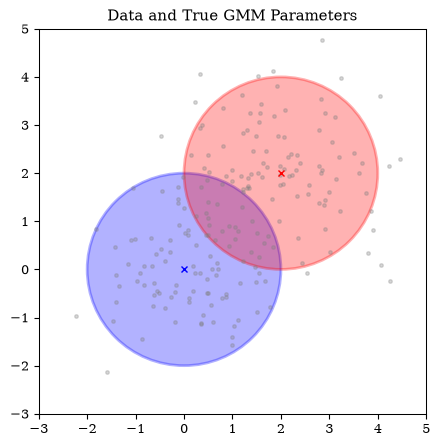

In [11]:
n_components = 2
pi = np.ones(n_components) / n_components
mus = [np.array([0., 0.]), np.array([2, 2])]
covs = [np.eye(2)]*2

DGP = GaussianMixtureModel(random_state=1234567891)
DGP._set_parameters(mus, covs, pi)

n_samples = 200
X, Z = DGP.sample(n_samples, random_state=1234567891)

plt.figure(figsize=(5,5))
plt.plot(X[:,0], X[:, 1], '.', color='gray', alpha=.3)
DGP.plot_2D_model(plt.gca(), 'br')
plt.title('Data and True GMM Parameters')
plt.xlim([-3, 5])
plt.ylim([-3, 5])
plt.show()

In [67]:
reload(vectorized_em_algorithm)
t0 = time()
indices = np.random.choice(n_samples, n_components, replace=False)
initial_theta = [[X[i].copy() for i in indices],
    [np.eye(2) for _ in range(n_components)],
    np.ones(n_components) / n_components]
GMM = vectorized_em_algorithm.GaussianMixtureModelVectorized()
GMM.fit(X, initial_theta=initial_theta)
t1 = time()
naive_time = t1-t0

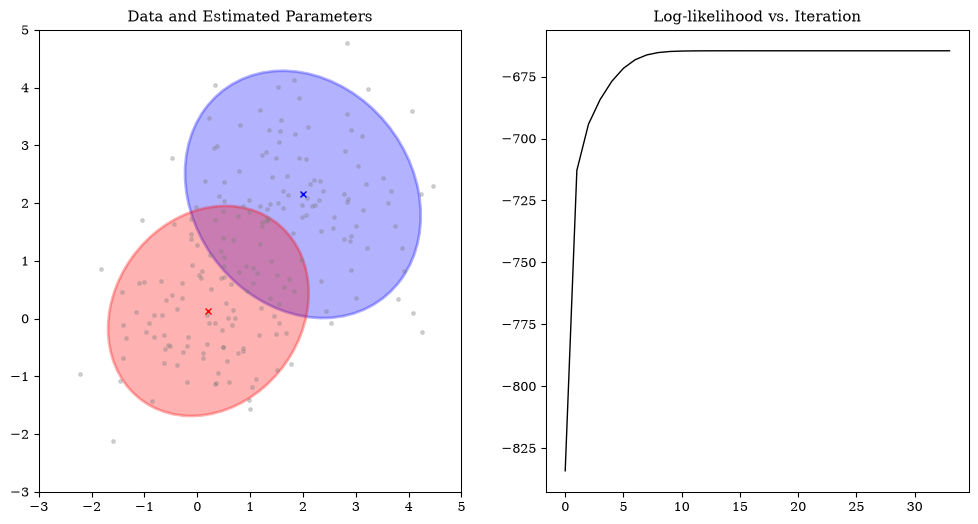

In [68]:
fig, axs = plt.subplots(1, 2, figsize=(12,6))
axs[0].plot(X[:,0], X[:, 1], '.', color='gray', alpha=.3)
GMM.plot_2D_model(axs[0], 'br')
axs[0].set_title('Data and Estimated Parameters')
axs[0].set_xlim([-3, 5])
axs[0].set_ylim([-3, 5])

axs[1].plot(GMM.log_likelihoods_, c='k')
axs[1].set_title('Log-likelihood vs. Iteration')
plt.show()

In [36]:
# Load the class from the file you just edited.
reload(vectorized_em_algorithm)
from vectorized_em_algorithm import GaussianMixtureModelVectorized

t0 = time()
GMM2 = GaussianMixtureModelVectorized()
GMM2.fit(X, initial_theta=initial_theta)
t1 = time()
vectorized_time = t1-t0

print(f"Vectorized code was {naive_time / vectorized_time:.2f} times faster!")

Vectorized code was 62.80 times faster!


In [ ]:
assert np.allclose(GMM.mu_, GMM2.mu_, atol=1e-5)

## Exercise 2: Make the Method Numerically Stable

Recall from lecture that the normalizing constant $\sum_{j=1}^K \pi_j \mathcal{N}(\mathbf{x}_i | \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)$ in the responsibilities can be very small if $\mathbf{x}_i$ is far from every cluster. If all weighted densities round to zero, direct normalization divides by zero. The supplied naïve E-step assigns uniform responsibilities in that case. Its log-likelihood calculation returns negative infinity when an observation has zero computed density.

Implement the log-sum-exp trick in `GaussianMixtureModelVectorized` to compute both the responsibilities in `_e_step` and the log-likelihood in `_compute_log_likelihood`. In the starter, update the shared `_component_terms` method to compute log-weighted densities directly. The cell below checks the score.

In [ ]:
# Reload the saved Exercise 2 implementation.
reload(vectorized_em_algorithm)
from vectorized_em_algorithm import GaussianMixtureModelVectorized

n_features = 50
n_components = 2
pi = np.ones(n_components) / n_components
covs = [np.eye(n_features)]*2

for scale in [.5, 1, 5, 50]:
    mus = [-scale*np.random.rand(n_features), scale*np.random.rand(n_features)]

    DGP = GaussianMixtureModel(random_state=1234567891)
    DGP._set_parameters(mus, covs, pi)

    n_samples = 200
    X, Z = DGP.sample(n_samples)

    GMM = GaussianMixtureModel()
    GMM2 = GaussianMixtureModelVectorized()

    GMM._set_parameters([np.zeros(n_features)]*2, covs, pi)
    GMM2._set_parameters([np.zeros(n_features)]*2, covs, pi)
    print(GMM.score(X), GMM2.score(X))

## Exercise 3: Document the Folk Theorem

How easily we can distinguish the two components depends on the distance between their means, $\|\mu_1-\mu_2\|$. When mixture components are harder to distinguish statistically (small separation), the Folk Theorem suggests several possible computational effects:
- More iterations/more time to converge (slow convergence)
- Higher variance in convergence time across initializations (sensitivity to initialization)
- Greater sensitivity e.g. in final log-likelihood to random initialization (getting stuck in local optima)

Generate one dataset at each separation. Fit that same dataset from different random starting values, and plot each metric as a function of separation. The loop below uses 100 starts per separation. Record whether each fit met the tolerance before interpreting its timing.

In [ ]:
def generate_data_with_separation(separation, n_samples=200, n_features=2, random_state=None):
    """
    Generate data from two Gaussian components with specified separation.
    
    Parameters
    ----------
    separation : float
        Distance between component means (Euclidean distance)
    n_samples : int, default=200
        Total number of samples to generate
    n_features : int, default=2
        Dimensionality
    random_state : int or None, default=None
        Random seed for reproducibility
    
    Returns
    -------
    X : array, shape (n_samples, n_features)
        Generated data points
    true_labels : array, shape (n_samples,)
        True component assignments (0 or 1)
    """
    # Create a GMM with known parameters
    DGP = GaussianMixtureModelVectorized(n_components=2)
    
    # Set true parameters manually
    mu1 = np.zeros(n_features)
    mu2 = separation * np.ones(n_features) / np.sqrt(n_features)
    
    cov = np.eye(n_features)
    
    DGP.mu_ = np.array([mu1, mu2])
    DGP.cov_ = np.array([cov]*2)
    DGP.pi_ = np.array([0.5, 0.5])
    
    # Sample from the GMM
    X, Z = DGP.sample(n_samples=n_samples, random_state=random_state)
    
    return X, Z

In [ ]:
n_iters = defaultdict(list)
log_likelihoods = defaultdict(list)
times = defaultdict(list)
converged = defaultdict(list)
seps = np.logspace(-.5, 2, 10)

for sep in seps:
    print(sep)
    np.random.seed(1234567891)
    X, _ = generate_data_with_separation(sep)
    for _ in tqdm(range(100)):
        GMM = GaussianMixtureModelVectorized()
        t0 = time()
        GMM.fit(X, verbose=False)
        t1 = time()
        
        times[sep].append(t1-t0)
        n_iters[sep].append(GMM.n_iter_)
        log_likelihoods[sep].append(GMM.log_likelihoods_[-1])
        converged[sep].append(GMM.converged_)

In [ ]:
plt.figure(figsize=(5,3))
plt.semilogx(seps, [np.mean(times[sep]) for sep in seps], 'b.-')
plt.xlabel('Separation')
plt.ylabel('Mean fit time (seconds)')
plt.tight_layout()
plt.savefig('time.pdf')
plt.show()

In [ ]:
# TODO: Plot iteration counts, variability in run time, and variability in
# final log likelihood against separation. Use converged to identify capped fits.